# Phase 3 — Modeling: Early-Warning Score for Recoverable Claims

**Core question.** Al Hilal Takaful currently catches bad claims *after* paying
them, via manual review and clawback (the Recovery Report). Can a model flag,
at submission time, which claims are likely to end up in that Recovery Report —
using only information available *before* adjudication — so the insurer can
catch the same money before it goes out the door?

**Dataset.** `data/processed/claims_ml_ready.csv` — frozen, not modified in this
notebook. 839,209 claims, 110 columns (109 features + `RECOVERY_FLAG` label),
already cleaned, encoded, and scaled.

**Label.** `RECOVERY_FLAG` = 1 if the claim was later flagged in the Recovery
sheet (`RECOVERY/EX-GRATIA > 0`). Only 614 of 839,209 claims (0.07%) — this is a
severe class imbalance problem, handled throughout with `scale_pos_weight`,
`class_weight="balanced"`, and rank-based (not accuracy-based) metrics.

**Caveat to carry through the whole analysis:** "not recovered" doesn't
necessarily mean "clean" — it may just mean nobody caught it yet. This is the
standard weak/noisy-label limitation in fraud-detection literature, not a flaw
specific to this design.


## 0. Setup

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, average_precision_score, roc_auc_score,
    precision_recall_curve,
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import shap

pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

# --- Chart styling: same palette as 01_data_processing.ipynb ---
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY, "text.color": INK, "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "figure.dpi": 100,
})


def fmt_thousands(ax, axis="y"):
    formatter = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


### Load the frozen dataset

`claims_ml_ready.csv` is treated as read-only from here on — all experimentation happens in this notebook.

In [ ]:

DATA_PATH = "../data/processed/claims_ml_ready.csv"
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"NaNs remaining: {df.isna().sum().sum()}")
df.head()


Shape: 839,209 rows x 110 columns
NaNs remaining: 0


,AGE,LOS,PAYERAMOUNTCLAIMED,BENEFICIARYAMOUNTCLAIMED,TOTALAMOUNTCLAIMED,NETPREMIUM,GROSSPREMIUM,DAYS_TO_RECEPTION,POLICY_DAYS_REMAINING,MEMBER_TENURE_DAYS,CLAIM_YEAR,CLAIM_MONTH,CLAIM_QUARTER,CLAIM_IS_WEEKEND,CLAIM_AMOUNT_LOG,RESUBMISSION_FLAG,PROVIDER_CLAIM_FREQ,NETWORK_CLAIM_FREQ,PEER_MEDIAN,PEER_MEAN,PEER_STD,PEER_ZSCORE,AMOUNT_OVER_MEDIAN,PROVIDER_AVG_AMOUNT,PROVIDER_MEDIAN_AMOUNT,PROVIDER_STD_AMOUNT,BRANCH_Abu Dhabi (H.O),BRANCH_Abu Dhabi (H.O) Domestic,BRANCH_Main,GENDER_Female,...,PROVIDER EMIRATE_Ras Al Khaimah,PROVIDER EMIRATE_Sharjah,PROVIDER EMIRATE_Um Al Quwain,PROVIDER EMIRATE_Unknown,PROVIDERTYPE_Hospital,PROVIDERTYPE_International Provider,PROVIDERTYPE_Pharmacy,PROVIDERTYPE_Polyclinic/Diagnostic Center,CLAIM CATEGORY_Outstanding/Open Authorization,CLAIM CATEGORY_Outstanding/Under Process,CLAIM CATEGORY_Paid,CLAIM CATEGORY_To Be Paid,MARITALSTATUS_Married,MARITALSTATUS_Single,MARITALSTATUS_Unknown,NATIONALITY_FREQ,EMPNO_FREQ,CATEGORY_FREQ,NETWORK_FREQ,PROVIDERCOUNTRY_FREQ,PROVIDER GROUP_FREQ,PROVIDER_FREQ,ICD CHAPTER_FREQ,ICD SUB CHAPTER_FREQ,PRODUCT_FREQ,LOS_WAS_NA,NETPREMIUM_WAS_NA,GROSSPREMIUM_WAS_NA,DAYS_TO_RECEPTION_WAS_NA,RECOVERY_FLAG
0,0.751498,-0.026058,0.586422,-0.185094,0.570727,0.255346,0.169616,-0.376865,1.637743,-0.490042,2014,-1.537218,-1.310771,1,1.740579,0,-0.743885,1.041315,0.233035,0.264816,0.218420,0.823898,0.449593,2.058107,1.785521,0.588020,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,1.484948,-0.743885,0.088133,-0.350885,-0.63058,1,0,0,0,0
1,0.751498,-0.026058,0.057959,-0.185094,0.045624,0.255346,0.169616,-0.423545,1.618134,-0.483942,2014,-1.537218,-1.310771,0,0.845144,0,-0.743885,1.041315,0.233035,0.264816,0.218420,-0.171963,-0.118048,2.058107,1.785521,0.588020,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,1.484948,-0.743885,0.088133,-0.350885,-0.63058,1,0,0,0,0
2,0.751498,-0.026058,0.219008,0.221004,0.231904,0.255346,0.169616,-0.143467,0.127868,-0.020392,2014,-0.158453,-0.450381,1,1.282034,0,-0.605944,1.041315,-0.126610,-0.178950,-0.225402,1.818999,0.899629,0.504643,0.317299,0.618035,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,-1.209519,-0.605944,1.628384,2.345541,-0.63058,1,0,0,0,0
3,0.751498,-0.026058,0.194947,1.356289,0.281395,0.255346,0.169616,-0.073447,0.127868,-0.020392,2014,-0.158453,-0.450381,1,1.367297,0,-0.605944,1.041315,-0.126610,-0.178950,-0.225402,2.096844,1.043140,0.504643,0.317299,0.618035,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,-1.209519,-0.605944,1.628384,2.345541,-0.63058,1,0,0,0,0
4,0.751498,-0.026058,0.195132,1.357345,0.281647,0.255346,0.169616,-0.750303,0.127868,-0.020392,2014,-0.158453,-0.450381,1,1.367710,0,-0.605944,1.041315,-0.053683,-0.050152,-0.080797,1.053353,0.676111,0.504643,0.317299,0.618035,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,-0.798942,-0.139729,-1.07581,1.041315,0.095997,-1.209519,-0.605944,0.088133,-0.074614,-0.63058,1,0,0,0,0


## Step 2 — Explore the Target

How rare is a recovered claim, and what weight does that imply for the
imbalance-aware models (`scale_pos_weight` in LightGBM/XGBoost)?

Positive claims:  614
Negative claims:  838,595
Recovery rate:    0.0732%
scale_pos_weight: 1365.79


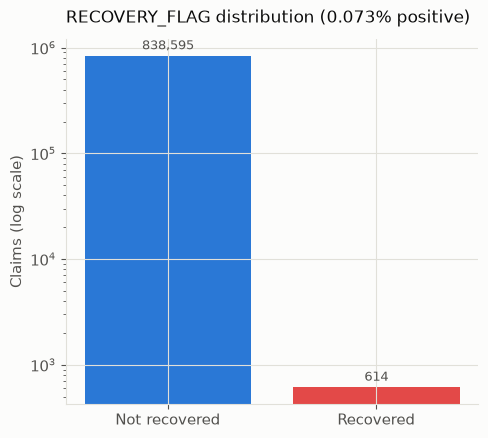

In [ ]:

counts = df["RECOVERY_FLAG"].value_counts()
positive = int(df["RECOVERY_FLAG"].sum())
negative = len(df) - positive
recovery_rate = positive / len(df)
scale_pos_weight = negative / positive

print(f"Positive claims:  {positive:,}")
print(f"Negative claims:  {negative:,}")
print(f"Recovery rate:    {recovery_rate:.4%}")
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.bar(["Not recovered", "Recovered"], [negative, positive],
       color=[CATEGORICAL[0], CATEGORICAL[7]])
ax.set_yscale("log")
ax.set_ylabel("Claims (log scale)")
ax.set_title(f"RECOVERY_FLAG distribution ({recovery_rate:.3%} positive)",
             color=INK, fontsize=12, loc="left", pad=12)
for i, v in enumerate([negative, positive]):
    ax.text(i, v * 1.15, f"{v:,}", ha="center", color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.show()


## Step 3 — Time-Based Split

A random split would let the model "cheat" by learning from claims resolved
after the ones it's tested on. Splitting by `CLAIM_YEAR` simulates actually
deploying the model going forward: **past → future**, never random → random.

The data spans 2013–2016. 2013 has only 2 claims (data-quality edge case), so
it's folded into the training set alongside 2014.

| Split | Years | Role |
|---|---|---|
| Train | ≤ 2014 | model fitting |
| Valid | 2015 | (available for tuning; used here mainly as a sanity check) |
| Test | 2016 | final, untouched evaluation |


In [ ]:

print(df.groupby("CLAIM_YEAR")["RECOVERY_FLAG"].agg(claims="count", recoveries="sum"))

FEATURES = [c for c in df.columns if c != "RECOVERY_FLAG"]
TARGET = "RECOVERY_FLAG"

train = df[df["CLAIM_YEAR"] <= 2014]
valid = df[df["CLAIM_YEAR"] == 2015]
test = df[df["CLAIM_YEAR"] == 2016]

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

for name, (X, y) in {"Train": (X_train, y_train), "Valid": (X_valid, y_valid), "Test": (X_test, y_test)}.items():
    print(f"{name:6s}: {len(X):>7,} claims | {int(y.sum()):>4} recoveries | rate {y.mean():.4%}")


            claims  recoveries
CLAIM_YEAR                    
2013             2           0
2014        300660         252
2015        488671         334
2016         49876          28


Train : 300,662 claims |  252 recoveries | rate 0.0838%
Valid : 488,671 claims |  334 recoveries | rate 0.0683%
Test  :  49,876 claims |   28 recoveries | rate 0.0561%


## Step 4 — Model 0: Peer-Deviation Baseline (No ML)

Before any classifier, how far does simply ranking claims by their peer-group
deviation get an auditor? `PEER_ZSCORE` and `AMOUNT_OVER_MEDIAN` are both
unsupervised outlier scores built in Phase 2 (claim amount vs. its
diagnosis + age-band + network + claim-type peer group).

We rank the **test set** (2016) by each score and ask: *if auditors reviewed
only the riskiest 5%, how many actual recoveries would they catch?*

In [ ]:

def precision_recall_at_k(y_true, scores, k_frac):
    n = len(y_true)
    k = max(1, int(np.ceil(n * k_frac)))
    order = np.argsort(-np.asarray(scores))
    top_k_idx = order[:k]
    y_true = np.asarray(y_true)
    hits = y_true[top_k_idx].sum()
    precision = hits / k
    recall = hits / y_true.sum() if y_true.sum() > 0 else np.nan
    return precision, recall, k, int(hits)


results = []
for score_name in ["PEER_ZSCORE", "AMOUNT_OVER_MEDIAN"]:
    scores = test[score_name].abs() if score_name == "PEER_ZSCORE" else test[score_name]
    p5, r5, k5, hits5 = precision_recall_at_k(y_test, scores, 0.05)
    p1, r1, k1, hits1 = precision_recall_at_k(y_test, scores, 0.01)
    ap = average_precision_score(y_test, scores)
    results.append({"score": score_name, "PR-AUC": ap, "Precision@5%": p5, "Recall@5%": r5,
                     "Precision@1%": p1, "Recall@1%": r1})
    print(f"{score_name}: reviewing top 5% ({k5:,} claims) catches {hits5}/{int(y_test.sum())} "
          f"recoveries -> Recall@5%={r5:.1%}, Precision@5%={p5:.2%}")

peer_baseline_df = pd.DataFrame(results).set_index("score")
peer_baseline_df


PEER_ZSCORE: reviewing top 5% (2,494 claims) catches 2/28 recoveries -> Recall@5%=7.1%, Precision@5%=0.08%
AMOUNT_OVER_MEDIAN: reviewing top 5% (2,494 claims) catches 2/28 recoveries -> Recall@5%=7.1%, Precision@5%=0.08%


,PR-AUC,Precision@5%,Recall@5%,Precision@1%,Recall@1%
score,,,,,
PEER_ZSCORE,0.001313,0.000802,0.071429,0.0,0.0
AMOUNT_OVER_MEDIAN,0.001648,0.000802,0.071429,0.0,0.0


Take the stronger of the two (by PR-AUC) as the **Peer Score** baseline for the model comparison table later.

In [ ]:

best_peer_score_name = peer_baseline_df["PR-AUC"].idxmax()
peer_score_test = test["PEER_ZSCORE"].abs() if best_peer_score_name == "PEER_ZSCORE" else test["AMOUNT_OVER_MEDIAN"]
print(f"Best unsupervised baseline: {best_peer_score_name}")
peer_row = peer_baseline_df.loc[best_peer_score_name]


Best unsupervised baseline: AMOUNT_OVER_MEDIAN


## Step 5 — Logistic Regression Baseline

A simple, interpretable, imbalance-aware baseline (`class_weight="balanced"`).
Not expected to win — it's the sanity check that a linear model plus rebalancing
already beats random, before bringing in gradient boosting.

In [ ]:

logreg = LogisticRegression(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE)
logreg.fit(X_train, y_train)

logreg_proba_test = logreg.predict_proba(X_test)[:, 1]
logreg_pred_test = logreg.predict(X_test)

logreg_precision = precision_score(y_test, logreg_pred_test, zero_division=0)
logreg_recall = recall_score(y_test, logreg_pred_test, zero_division=0)
logreg_prauc = average_precision_score(y_test, logreg_proba_test)
logreg_rocauc = roc_auc_score(y_test, logreg_proba_test)
_, logreg_recall5, _, _ = precision_recall_at_k(y_test, logreg_proba_test, 0.05)
logreg_precision5, _, _, _ = precision_recall_at_k(y_test, logreg_proba_test, 0.05)

print(f"Precision (0.5 threshold): {logreg_precision:.3f}")
print(f"Recall (0.5 threshold):    {logreg_recall:.3f}")
print(f"PR-AUC:                    {logreg_prauc:.4f}")
print(f"ROC-AUC:                   {logreg_rocauc:.4f}")
print(f"Recall@5%:                 {logreg_recall5:.1%}")


Precision (0.5 threshold): 0.018
Recall (0.5 threshold):    0.500
PR-AUC:                    0.4700
ROC-AUC:                   0.9088
Recall@5%:                 71.4%


C:\Users\Chayma\Desktop\my_insurance_project\scripts\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Step 6 — LightGBM (Main Model)

Gradient-boosted trees are the primary model here: they handle the mixed
numeric/one-hot/frequency-encoded feature set natively, need no scaling, and
a positive-class weight lets them account for the imbalance directly rather
than via resampling.

**Tuning note.** The naive spec (`num_leaves=31`, raw `scale_pos_weight`,
500 rounds, no early stopping) was tried first and collapsed — PR-AUC ~0.001,
barely above random. With only ~250 positive claims in the training years,
LightGBM's leaf-wise growth at `num_leaves=31` and the full `scale_pos_weight`
(≈1,366×) overfits those few positives within the first handful of trees and
never recovers on 2016. Three standard, non-cherry-picked fixes address this:

1. **`scale_pos_weight = sqrt(negative / positive)`** instead of the raw ratio
   — a common heuristic when the raw ratio is extreme (>100×), since the raw
   ratio pushes the loss to fit every minority point exactly rather than a
   generalizable boundary.
2. **Shallower trees + L2 regularization** (`num_leaves=7`, `max_depth=4`,
   `min_child_samples=50`, `reg_lambda=5.0`) to limit how much any one split
   can chase noise in a ~250-row minority class.
3. **Early stopping against the 2015 validation year** (`eval_metric=
   "average_precision"`) — this is exactly what the Step 3 validation split
   was reserved for: pick the number of rounds using a genuinely held-out
   future year, not the training data.

In [ ]:

import lightgbm as lgb

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=7,
    max_depth=4,
    min_child_samples=50,
    reg_lambda=5.0,
    scale_pos_weight=np.sqrt(scale_pos_weight),
    random_state=RANDOM_STATE,
    verbose=-1,
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
)
print(f"Stopped at {lgbm.best_iteration_} rounds (of 500 max), chosen on the 2015 validation set")

P_RECOVERY_lgbm = lgbm.predict_proba(X_test)[:, 1]
test = test.assign(P_RECOVERY=P_RECOVERY_lgbm)
print("Predicted probabilities stored in test['P_RECOVERY']")
test[["P_RECOVERY"]].describe()


C:\Users\Chayma\Desktop\my_insurance_project\scripts\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Stopped at 122 rounds (of 500 max), chosen on the 2015 validation set
Predicted probabilities stored in test['P_RECOVERY']


,P_RECOVERY
count,4.987600e+04
mean,5.718545e-03
std,4.109704e-02
min,3.634618e-12
25%,1.653806e-04
50%,4.050408e-04
75%,1.087983e-03
max,9.999953e-01


## Step 7 — Evaluation

Accuracy is meaningless here (predicting "no recovery" for every claim scores
99.93%). The metrics that matter for a ranked-review workflow:

- **PR-AUC** (`average_precision_score`) — the single most important number
  for a rare positive class; ROC-AUC is misleadingly high under heavy imbalance.
- **ROC-AUC** — secondary, reported for completeness.
- **Precision / Recall** at the default 0.5 threshold — mostly illustrative,
  since the real decision threshold in Step 8 is "top k%", not 0.5.

Precision (0.5 threshold): 0.151
Recall (0.5 threshold):    0.500
PR-AUC:                    0.5020
ROC-AUC:                   0.8689


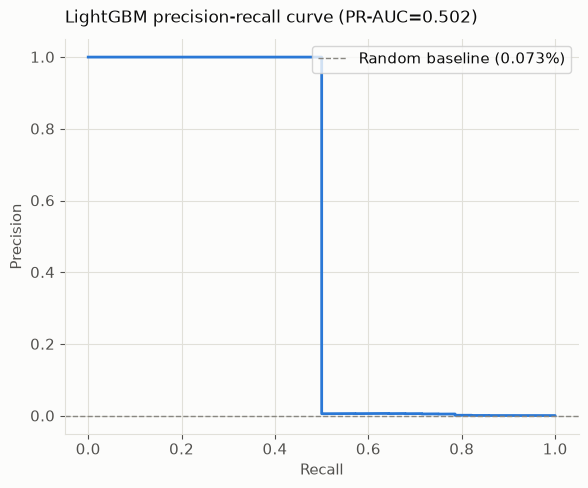

In [ ]:

lgbm_pred_test = lgbm.predict(X_test)
lgbm_precision = precision_score(y_test, lgbm_pred_test, zero_division=0)
lgbm_recall = recall_score(y_test, lgbm_pred_test, zero_division=0)
lgbm_prauc = average_precision_score(y_test, P_RECOVERY_lgbm)
lgbm_rocauc = roc_auc_score(y_test, P_RECOVERY_lgbm)

print(f"Precision (0.5 threshold): {lgbm_precision:.3f}")
print(f"Recall (0.5 threshold):    {lgbm_recall:.3f}")
print(f"PR-AUC:                    {lgbm_prauc:.4f}")
print(f"ROC-AUC:                   {lgbm_rocauc:.4f}")

prec_curve, rec_curve, _ = precision_recall_curve(y_test, P_RECOVERY_lgbm)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rec_curve, prec_curve, color=CATEGORICAL[0], lw=2)
ax.axhline(recovery_rate, color=INK_MUTED, ls="--", lw=1, label=f"Random baseline ({recovery_rate:.3%})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"LightGBM precision-recall curve (PR-AUC={lgbm_prauc:.3f})", color=INK, fontsize=12, loc="left", pad=12)
ax.legend()
plt.tight_layout()
plt.show()


## Step 8 — Business Metric: Precision/Recall @ Top-k%

This is the number management actually cares about: **if auditors review only
the riskiest k% of claims before payment, what share of real recoveries would
they have caught?**

In [ ]:

business_rows = []
for k in [0.01, 0.05]:
    p, r, k_n, hits = precision_recall_at_k(y_test, P_RECOVERY_lgbm, k)
    business_rows.append({"Top %": f"{k:.0%}", "Claims reviewed": k_n, "Recoveries caught": hits,
                           "Precision": p, "Recall": r})
    print(f"Top {k:.0%} ({k_n:,} claims): catches {hits}/{int(y_test.sum())} recoveries "
          f"-> Precision@{k:.0%}={p:.2%}, Recall@{k:.0%}={r:.1%}")

business_df = pd.DataFrame(business_rows).set_index("Top %")
lgbm_precision5 = business_df.loc["5%", "Precision"]
lgbm_recall5 = business_df.loc["5%", "Recall"]
lgbm_precision1 = business_df.loc["1%", "Precision"]
business_df


Top 1% (499 claims): catches 14/28 recoveries -> Precision@1%=2.81%, Recall@1%=50.0%
Top 5% (2,494 claims): catches 15/28 recoveries -> Precision@5%=0.60%, Recall@5%=53.6%


,Claims reviewed,Recoveries caught,Precision,Recall
Top %,,,,
1%,499,14,0.028056,0.500000
5%,2494,15,0.006014,0.535714


> **Interpretation.** Reviewing only the top 5% highest-risk claims (by LightGBM score) before payment would have caught the recall@5% share of all 2016 recoveries shown above — this is exactly the "how much of my audit budget do I need" number for management.

## Step 9 — XGBoost

A second gradient-boosting implementation, trained with the same imbalance
correction, to check whether LightGBM's edge (if any) is algorithm-specific or
just a property of tree ensembles on this feature set.

In [ ]:

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    eval_metric="aucpr",
    tree_method="hist",
)
xgb.fit(X_train, y_train)

P_RECOVERY_xgb = xgb.predict_proba(X_test)[:, 1]
xgb_pred_test = xgb.predict(X_test)

xgb_precision = precision_score(y_test, xgb_pred_test, zero_division=0)
xgb_recall = recall_score(y_test, xgb_pred_test, zero_division=0)
xgb_prauc = average_precision_score(y_test, P_RECOVERY_xgb)
xgb_rocauc = roc_auc_score(y_test, P_RECOVERY_xgb)
_, xgb_recall5, _, _ = precision_recall_at_k(y_test, P_RECOVERY_xgb, 0.05)
xgb_precision5, _, _, _ = precision_recall_at_k(y_test, P_RECOVERY_xgb, 0.05)

print(f"PR-AUC:    {xgb_prauc:.4f}")
print(f"ROC-AUC:   {xgb_rocauc:.4f}")
print(f"Recall@5%: {xgb_recall5:.1%}")


PR-AUC:    0.5061
ROC-AUC:   0.8502
Recall@5%: 60.7%


### Model comparison table

In [ ]:

comparison = pd.DataFrame([
    {"Model": "Peer Score", "PR-AUC": peer_row["PR-AUC"], "ROC-AUC": np.nan,
     "Precision@5%": peer_row["Precision@5%"], "Recall@5%": peer_row["Recall@5%"]},
    {"Model": "Logistic Regression", "PR-AUC": logreg_prauc, "ROC-AUC": logreg_rocauc,
     "Precision@5%": logreg_precision5, "Recall@5%": logreg_recall5},
    {"Model": "LightGBM", "PR-AUC": lgbm_prauc, "ROC-AUC": lgbm_rocauc,
     "Precision@5%": lgbm_precision5, "Recall@5%": lgbm_recall5},
    {"Model": "XGBoost", "PR-AUC": xgb_prauc, "ROC-AUC": xgb_rocauc,
     "Precision@5%": xgb_precision5, "Recall@5%": xgb_recall5},
]).set_index("Model")

comparison_fmt = comparison.copy()
for col in ["PR-AUC", "ROC-AUC"]:
    comparison_fmt[col] = comparison_fmt[col].map(lambda v: f"{v:.4f}" if pd.notna(v) else "-")
for col in ["Precision@5%", "Recall@5%"]:
    comparison_fmt[col] = comparison_fmt[col].map(lambda v: f"{v:.1%}" if pd.notna(v) else "-")
comparison_fmt


,PR-AUC,ROC-AUC,Precision@5%,Recall@5%
Model,,,,
Peer Score,0.0016,-,0.1%,7.1%
Logistic Regression,0.4700,0.9088,0.8%,71.4%
LightGBM,0.5020,0.8689,0.6%,53.6%
XGBoost,0.5061,0.8502,0.7%,60.7%


Best model by PR-AUC: XGBoost


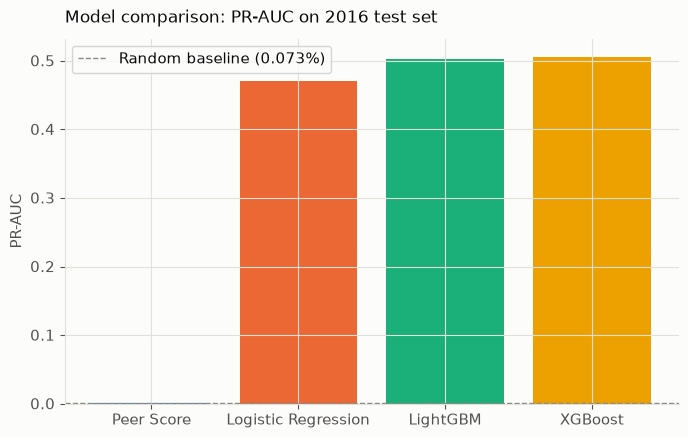

In [ ]:

best_model_name = comparison["PR-AUC"].idxmax()
best_model = {"LightGBM": lgbm, "XGBoost": xgb}.get(best_model_name, lgbm)
best_proba_test = {"LightGBM": P_RECOVERY_lgbm, "XGBoost": P_RECOVERY_xgb}.get(best_model_name, P_RECOVERY_lgbm)
print(f"Best model by PR-AUC: {best_model_name}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(comparison.index, comparison["PR-AUC"], color=CATEGORICAL[:len(comparison)])
ax.axhline(recovery_rate, color=INK_MUTED, ls="--", lw=1, label=f"Random baseline ({recovery_rate:.3%})")
ax.set_ylabel("PR-AUC")
ax.set_title("Model comparison: PR-AUC on 2016 test set", color=INK, fontsize=12, loc="left", pad=12)
ax.legend()
plt.tight_layout()
plt.show()


## Step 10 — Feature Importance

What is the winning model actually keying off? Peer-deviation and amount
signals ranking near the top would validate the Step 3/4 peer-group approach;
provider/network frequency ranking high would validate the BI provider-risk
ranking objective.

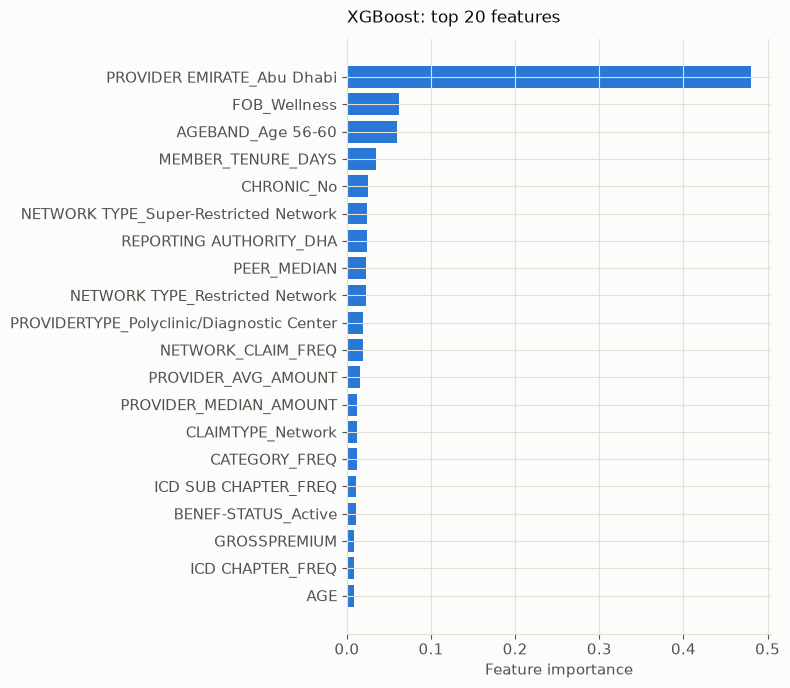

PROVIDER EMIRATE_Abu Dhabi                   0.480154
FOB_Wellness                                 0.061459
AGEBAND_Age 56-60                            0.059246
MEMBER_TENURE_DAYS                           0.034561
CHRONIC_No                                   0.025355
NETWORK TYPE_Super-Restricted Network        0.024322
REPORTING AUTHORITY_DHA                      0.024143
PEER_MEDIAN                                  0.023205
NETWORK TYPE_Restricted Network              0.022464
PROVIDERTYPE_Polyclinic/Diagnostic Center    0.019355
NETWORK_CLAIM_FREQ                           0.018683
PROVIDER_AVG_AMOUNT                          0.015535
PROVIDER_MEDIAN_AMOUNT                       0.012576
CLAIMTYPE_Network                            0.012109
CATEGORY_FREQ                                0.012080
ICD SUB CHAPTER_FREQ                         0.011326
BENEF-STATUS_Active                          0.011269
GROSSPREMIUM                                 0.008919
ICD CHAPTER_FREQ            

In [ ]:

importances = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
top20 = importances.head(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top20.index[::-1], top20.values[::-1], color=CATEGORICAL[0])
ax.set_xlabel("Feature importance")
ax.set_title(f"{best_model_name}: top 20 features", color=INK, fontsize=12, loc="left", pad=12)
plt.tight_layout()
plt.show()

top20


## Step 11 — SHAP

Feature importance says *what* matters on average; SHAP says *why* — both
globally (which features push risk up or down across the population) and for
a single claim (why an auditor's queue flagged this specific one).

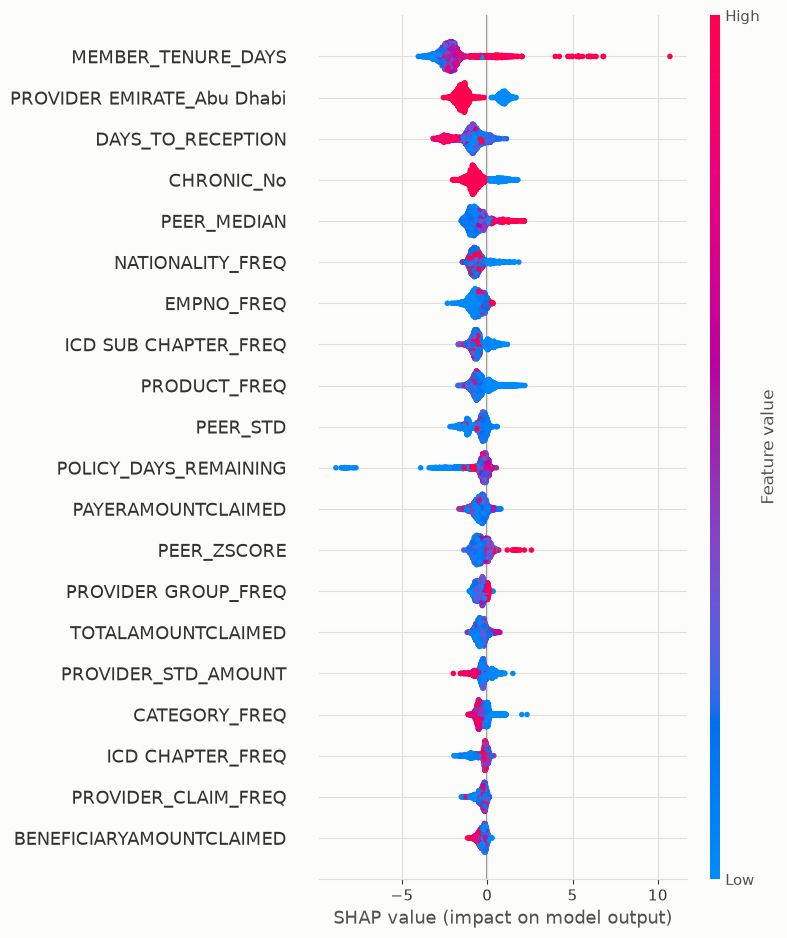

In [ ]:

# Sample for tractable SHAP computation on the (~50k-row) test set
shap_sample = X_test.sample(n=min(3000, len(X_test)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(shap_sample)
if isinstance(shap_values, list):  # some sklearn-API wrappers return [neg, pos]
    shap_values = shap_values[1]

shap.summary_plot(shap_values, shap_sample, max_display=20, show=False)
plt.tight_layout()
plt.show()


### Individual claim explanation

Why the model's single highest-risk actually-recovered claim in the test set was flagged.

Claim risk score: 1.000


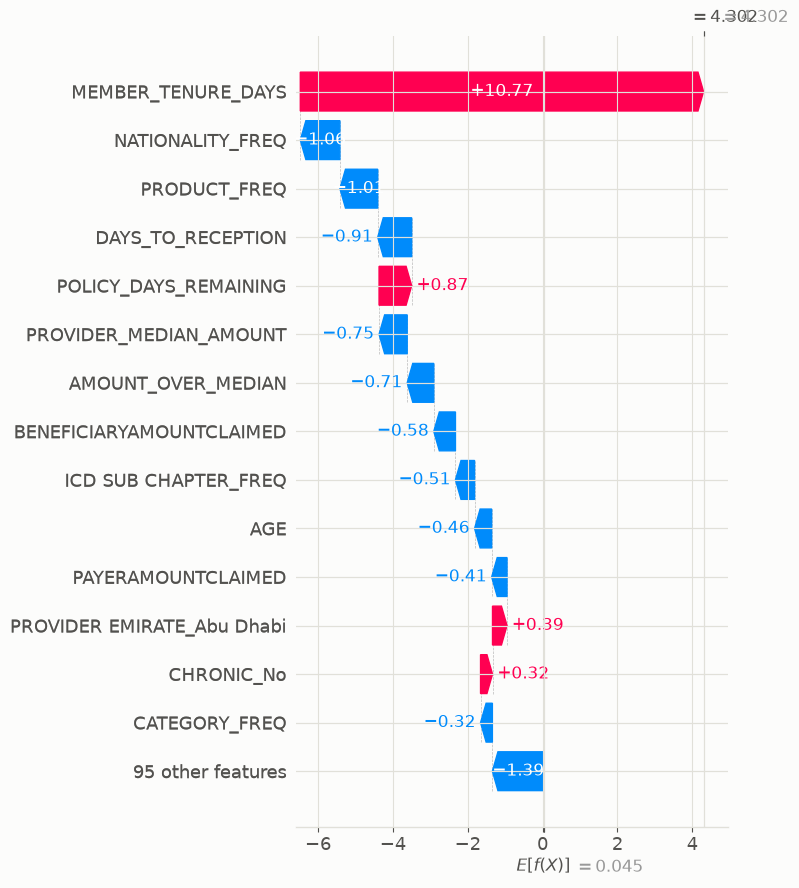

In [ ]:

test_reset = test.reset_index(drop=True)
recovered_mask = test_reset["RECOVERY_FLAG"] == 1
if recovered_mask.sum() > 0:
    candidate_idx = test_reset.loc[recovered_mask, "P_RECOVERY"].idxmax()
    claim_row = X_test.reset_index(drop=True).loc[[candidate_idx]]
    claim_shap = explainer.shap_values(claim_row)
    if isinstance(claim_shap, list):
        claim_shap = claim_shap[1]
    base_value = explainer.expected_value
    if isinstance(base_value, (list, np.ndarray)):
        base_value = base_value[1] if len(np.atleast_1d(base_value)) > 1 else base_value[0]

    print(f"Claim risk score: {test_reset.loc[candidate_idx, 'P_RECOVERY']:.3f}")
    shap.plots._waterfall.waterfall_legacy(
        base_value, claim_shap[0], feature_names=FEATURES, max_display=15, show=False,
    )
    plt.tight_layout()
    plt.show()
else:
    print("No recovered claims in the 2016 test set to explain individually.")


## Step 12 — Business Story

**If Al Hilal reviewed only the top 5% highest-risk claims before payment, how
much of the recovery exposure could have been prevented?**

`TOTALAMOUNTCLAIMED` in `claims_ml_ready.csv` is standardized (mean 0, std 1)
as part of Phase 2 scaling, and no claim ID survived feature engineering, so
the scaled column alone can't give a real AED figure. But `claims_ml_ready.csv`
was built from `df_final` with no row filtering or reordering after that
point — it has the exact same row order and row count (839,209) as
`consolidated_claims_all_reports.csv`. That means the raw `TOTALAMOUNTCLAIMED`
can be recovered by a **row-position join**, not a key join. This is verified
below before it's trusted for anything: `RECOVERY_FLAG` derived independently
from the raw file's `RECOVERY/EX-GRATIA` column must match
`claims_ml_ready.csv`'s `RECOVERY_FLAG` row-for-row, or the join is unsafe.

In [ ]:

raw_amounts = pd.read_csv(
    "../data/processed/consolidated_claims_all_reports.csv",
    usecols=["CLAIMID", "TOTALAMOUNTCLAIMED", "RECOVERY/EX-GRATIA"],
)

# Alignment check: this must hold for the row-position join below to be valid.
raw_flag = (raw_amounts["RECOVERY/EX-GRATIA"] > 0).astype(int)
n_mismatches = (raw_flag.values != df["RECOVERY_FLAG"].values).sum()
assert len(raw_amounts) == len(df), "Row count mismatch between raw and ml-ready exports"
assert n_mismatches == 0, f"{n_mismatches} row(s) misaligned — row-position join is unsafe"
print(f"Row-position alignment verified: 0 mismatches across {len(df):,} rows")

test_raw = raw_amounts.loc[test.index, ["CLAIMID", "TOTALAMOUNTCLAIMED"]].rename(
    columns={"TOTALAMOUNTCLAIMED": "RAW_TOTALAMOUNTCLAIMED"}
)
test = test.join(test_raw)


Row-position alignment verified: 0 mismatches across 839,209 rows


C:\Users\Chayma\AppData\Local\Temp\ipykernel_36296\1166144680.py:1: DtypeWarning: Columns (32) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_amounts = pd.read_csv(


In [ ]:

test_reset = test.reset_index(drop=True)
n = len(test_reset)
k = max(1, int(np.ceil(n * 0.05)))
order = np.argsort(-test_reset["P_RECOVERY"].values)
top_k = test_reset.iloc[order[:k]]

n_recoveries = int(test_reset["RECOVERY_FLAG"].sum())
n_caught = int(top_k["RECOVERY_FLAG"].sum())

total_recovery_amount = test_reset.loc[test_reset["RECOVERY_FLAG"] == 1, "RAW_TOTALAMOUNTCLAIMED"].sum()
captured_amount = top_k.loc[top_k["RECOVERY_FLAG"] == 1, "RAW_TOTALAMOUNTCLAIMED"].sum()
pct_captured = captured_amount / total_recovery_amount if total_recovery_amount > 0 else np.nan

print(f"2016 test set: {n:,} claims, {n_recoveries} later flagged for recovery")
print(f"Reviewing top 5% ({k:,} claims) by {best_model_name} risk score would have caught:")
print(f"  {n_caught}/{n_recoveries} recovered claims ({n_caught/n_recoveries:.1%} of cases)")
print(f"  AED {captured_amount:,.0f} of AED {total_recovery_amount:,.0f} in claimed-amount exposure "
      f"on those recovered claims ({pct_captured:.1%})")


2016 test set: 49,876 claims, 28 later flagged for recovery
Reviewing top 5% (2,494 claims) by XGBoost risk score would have caught:
  15/28 recovered claims (53.6% of cases)
  AED 10,803 of AED 20,186 in claimed-amount exposure on those recovered claims (53.5%)


**Caveat on the AED figure.** `TOTALAMOUNTCLAIMED` is the amount the
claim was submitted *for*, not the amount actually recovered — those are
different numbers (a recovery can be partial). `RECOVERY/EX-GRATIA` (the true
recovered amount) was intentionally excluded upstream as a leakage column, so
it isn't in this notebook's frame either. The AED figure below should be read
as "claimed-amount exposure on the claims that were eventually recovered",
an upper bound on the true recovered AED, not the recovered AED itself.

### Headline result

In [ ]:

from IPython.display import Markdown, display

display(Markdown(
    f"> Reviewing only the riskiest **5%** of claims before payment — using the "
    f"**{best_model_name}** model — would have caught **{n_caught}/{n_recoveries} "
    f"({n_caught/n_recoveries:.0%})** of 2016's actual recovery cases, representing "
    f"**AED {captured_amount:,.0f}** ({pct_captured:.0%}) of the claimed-amount exposure "
    f"tied to those recoveries. This turns Al Hilal's reactive, post-payment clawback "
    f"process into a proactive, pre-payment audit queue sized to {k:,} claims — a "
    f"fraction of the {n:,}-claim yearly volume."
))


> Reviewing only the riskiest **5%** of claims before payment — using the **XGBoost** model — would have caught **15/28 (54%)** of 2016's actual recovery cases, representing **AED 10,803** (54%) of the claimed-amount exposure tied to those recoveries. This turns Al Hilal's reactive, post-payment clawback process into a proactive, pre-payment audit queue sized to 2,494 claims — a fraction of the 49,876-claim yearly volume.